# 10-Bootloader升级：分段下载、固件替换与异常处理


## 1. 本篇范围与资料依据

第09篇把升级请求标志写入Flash参数区，再复位主控。本篇从Bootloader读取这个标志开始，沿着**重新查询任务 → 分段下载到Backup → 上报下载完成 → 覆盖App → 保存版本、清标志 → 跳转App**的顺序走完课程最后一段。

对应原课程视频42—47，参考讲义物理页69、73—75：

| 视频 | 本篇重点 | 自动字幕末时间 |
| --- | --- | --- |
| 42 新固件下载的处理流程 | Bootloader入口、三层状态、命令表 | 09:31.310 |
| 43 分段下载固件数据到备份区 | Range、URL格式化、解析二进制、偏移推进 | 18:53.900 |
| 44 上报下载完成消息 | 101、case作用域、OLED下载进度 | 10:15.660 |
| 45 替换Backup到App固件 | 1 KiB搬运、512/1024实验、任务状态影响 | 17:59.300 |
| 46 升级完成消息的异常处理 | AT共享WAIT状态、201未发送、延时补丁 | 05:43.240 |
| 47 传输协议与通信模组知识扩展 | MQTT、BLE、LoRa/NB-IoT、差分升级 | 03:28.550 |

本次已完整读取这六段的自动字幕，并对照配套 `05_GD32F407_OTA_Bootloader_InFlash`、App固件样本、讲义原图和OneNET接口文档。自动字幕可能有术语误识别，函数名、常量和操作顺序以源码核对。**未逐帧完整观看视频，未Keil编译、烧录、接板联调，也未向真实云任务发送请求。**

课程链接：[百度网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`。笔记中的SSID、密码、产品、设备及Token均使用占位值；配套原实现与“补充改进”明确分开。

先记住三个区别：

- **收到全部字节、写入Backup、验证镜像正确**是三个条件。原工程没有实际执行固件MD5计算与比对。
- **App区写完、App能正常启动、云端显示升级完成**是三个结果。原工程没有试运行确认或自动回滚。
- 原图的“备份区”在本实现里存放**待安装的新镜像**，并未另外保存旧App。


## 2. Bootloader入口：升级标志决定下载还是启动App

`Task_init()`初始化OLED、按键、Wi-Fi；`App_Wifi_Init()`调用 `InitSysParam()`读取参数。主循环调用协作式调度器，Wi-Fi任务目标周期仍为2 ms。

Bootloader和App的首要区别出现在 `App_Wifi_Task()`：

```c
void App_Wifi_Task(void){ // 2ms

    // 判断是否需要升级
    bool isNeedUpdate = CheckNeedUpdate();
    if(isNeedUpdate){
        WifiCommState_t commState = OtaDownloadFile(); // 下载过程中, 返回的是WIFI_COMM_WAIT
        
        if(commState == WIFI_COMM_OK){ // 下载新固件成功
            printf("OTA update success\r\n");
            
            // 执行固件烧录 (会产生阻塞)
            OtaFlashFile();
            // 存储新版本号
            SetSoftwareVersionParam(g_otaVerNo);
            // 清理升级标记
            ClearUpdateVerFlag();        
        }else if(commState == WIFI_COMM_FAIL){
            printf("OTA update fail\r\n");
            // 清理升级标记
            ClearUpdateVerFlag();        
        }
        
    }else {
        printf("========== Boot to App =============\r\n");
        BootToApp();
    }
}
```

读代码时先区分三态：

| OtaDownloadFile返回 | 本次回调做什么 |
| --- | --- |
| WIFI_COMM_WAIT | 下载/等待尚未结束，回调返回，下轮继续 |
| WIFI_COMM_OK | 调用OtaFlashFile，再设置版本和清标志 |
| WIFI_COMM_FAIL | 清升级标志，保留未被覆盖的App |
| 无升级标志 | 不进行OTA，调用BootToApp |

成功路径没有在 `OtaFlashFile()` 后直接调用 `BootToApp()`，而是先清标志，**后续调度再次进入时**走else启动App。2 ms只是计划周期，Flash操作、打印和延时会阻塞，不能把它理解为“任何情况下2 ms后保证跳转”。

原日志 `OTA update success` 在搬运前就打印，因此只能表示下载子流程已返回OK。不能靠这行日志证明新App已经烧录、验证或运行成功。

下载失败后清标志的课堂目的，是避免设备永远停在升级入口；这只有在旧App仍有效时才有意义。后面会单独讨论复制阶段的断电和失败边界。


## 3. 分区：为什么先下载Backup，再修改App

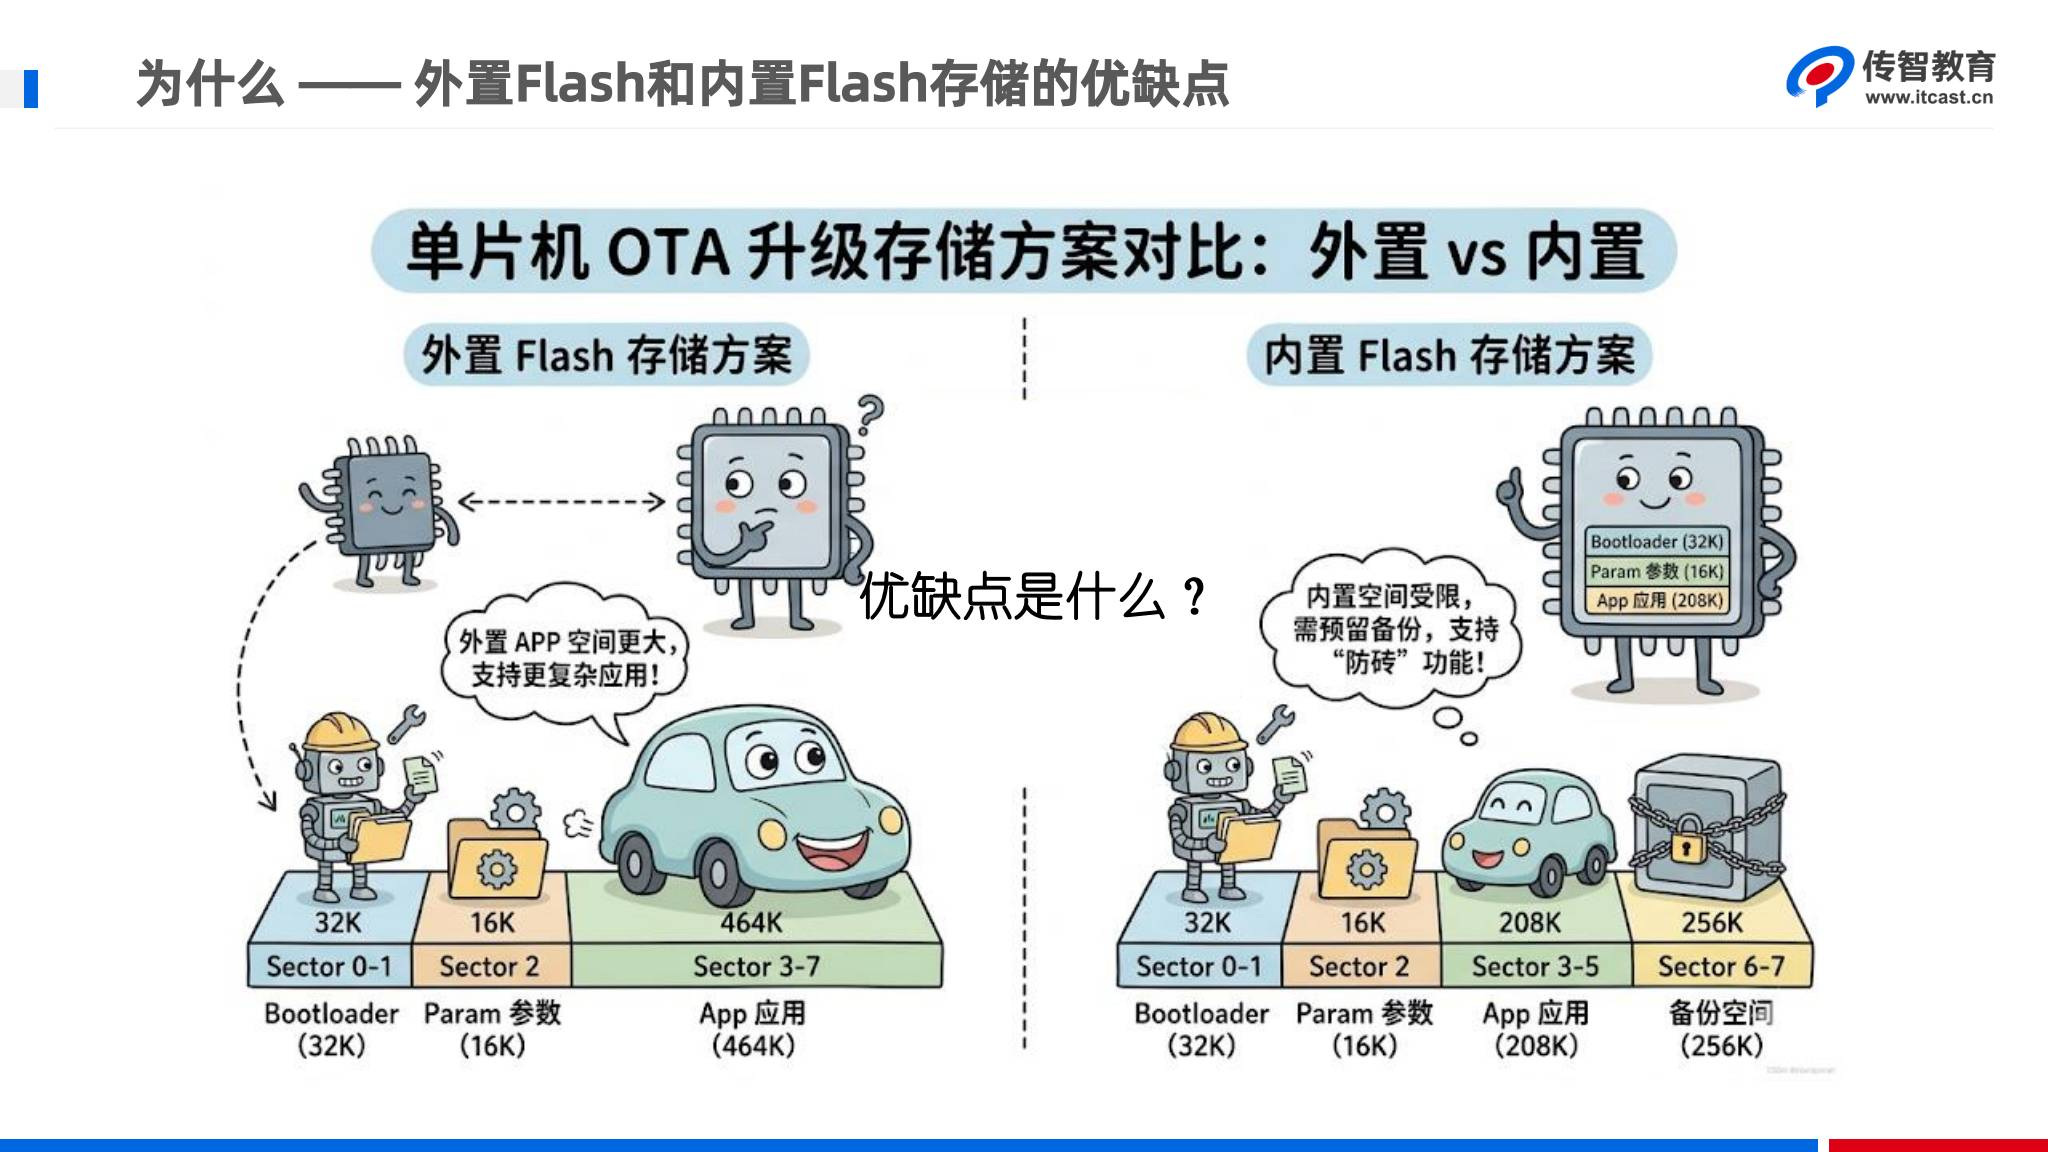

*讲义第74页。本文采用右侧内置Flash方案。图中的“防砖”是设计目标，具体能力还取决于校验、复制和恢复逻辑。*

配套 `store_app.h` 的实际布局：

| 分区 | 起始地址 | 结束地址，含末字节 | 容量 | 本篇职责 |
| --- | --- | --- | --- | --- |
| Bootloader | 0x08000000 | 0x08007FFF | 32 KiB | 下载、安装、引导 |
| Param | 0x08008000 | 0x0800BFFF | 16 KiB | magic、版本、升级标志、校验存储 |
| App | 0x0800C000 | 0x0803FFFF | 208 KiB | 可执行应用镜像 |
| Backup | 0x08040000 | 0x0807FFFF | 256 KiB | 临时保存待安装的新镜像 |

```c
#define FLASH_SIZE       0x80000
#define BOOTLOADER_SIZE  (32 * 1024)
#define PARAMETER_SIZE   (16 * 1024)
#define BACKUP_SIZE      (256 * 1024)
#define APP_SIZE \
    (FLASH_SIZE - BOOTLOADER_SIZE - PARAMETER_SIZE - BACKUP_SIZE)
#define FLASH_PAGE_SIZE  0x400  /* 这里是1 KiB搬运块 */

#define PARAM_ADDR_IN_FLASH  (0x08000000 + BOOTLOADER_SIZE)
#define APP_ADDR_IN_FLASH \
    (0x08000000 + BOOTLOADER_SIZE + PARAMETER_SIZE)
#define BACKUP_ADDR_IN_FLASH \
    (0x08000000 + FLASH_SIZE - BACKUP_SIZE)
#define NEED_UPDATE_VERSION_FLAG 0xABCD
```

Bootloader把下载地址设为 `BACKUP_ADDR_IN_FLASH + offset`，先保留现有App。下载过程中网络中断、任务失败时，只要尚未擦除App，旧应用仍有机会正常启动。

**镜像大小必须受App的208 KiB约束，而非只看Backup的256 KiB。** 能放进Backup，不代表能安装进App。应在擦除、下载前验证 `0 < size <= APP_SIZE`，并验证完整包类型；配套原解析器没有落实所有这些条件。

新镜像虽然临时放在0x08040000，其链接执行地址仍应是App地址0x0800C000。Backup是暂存位置，不能因此把应用链接到Backup地址，也不能直接把Backup向量表当现有启动配置使用。


## 4. 主状态和下载子状态：两层都要走完

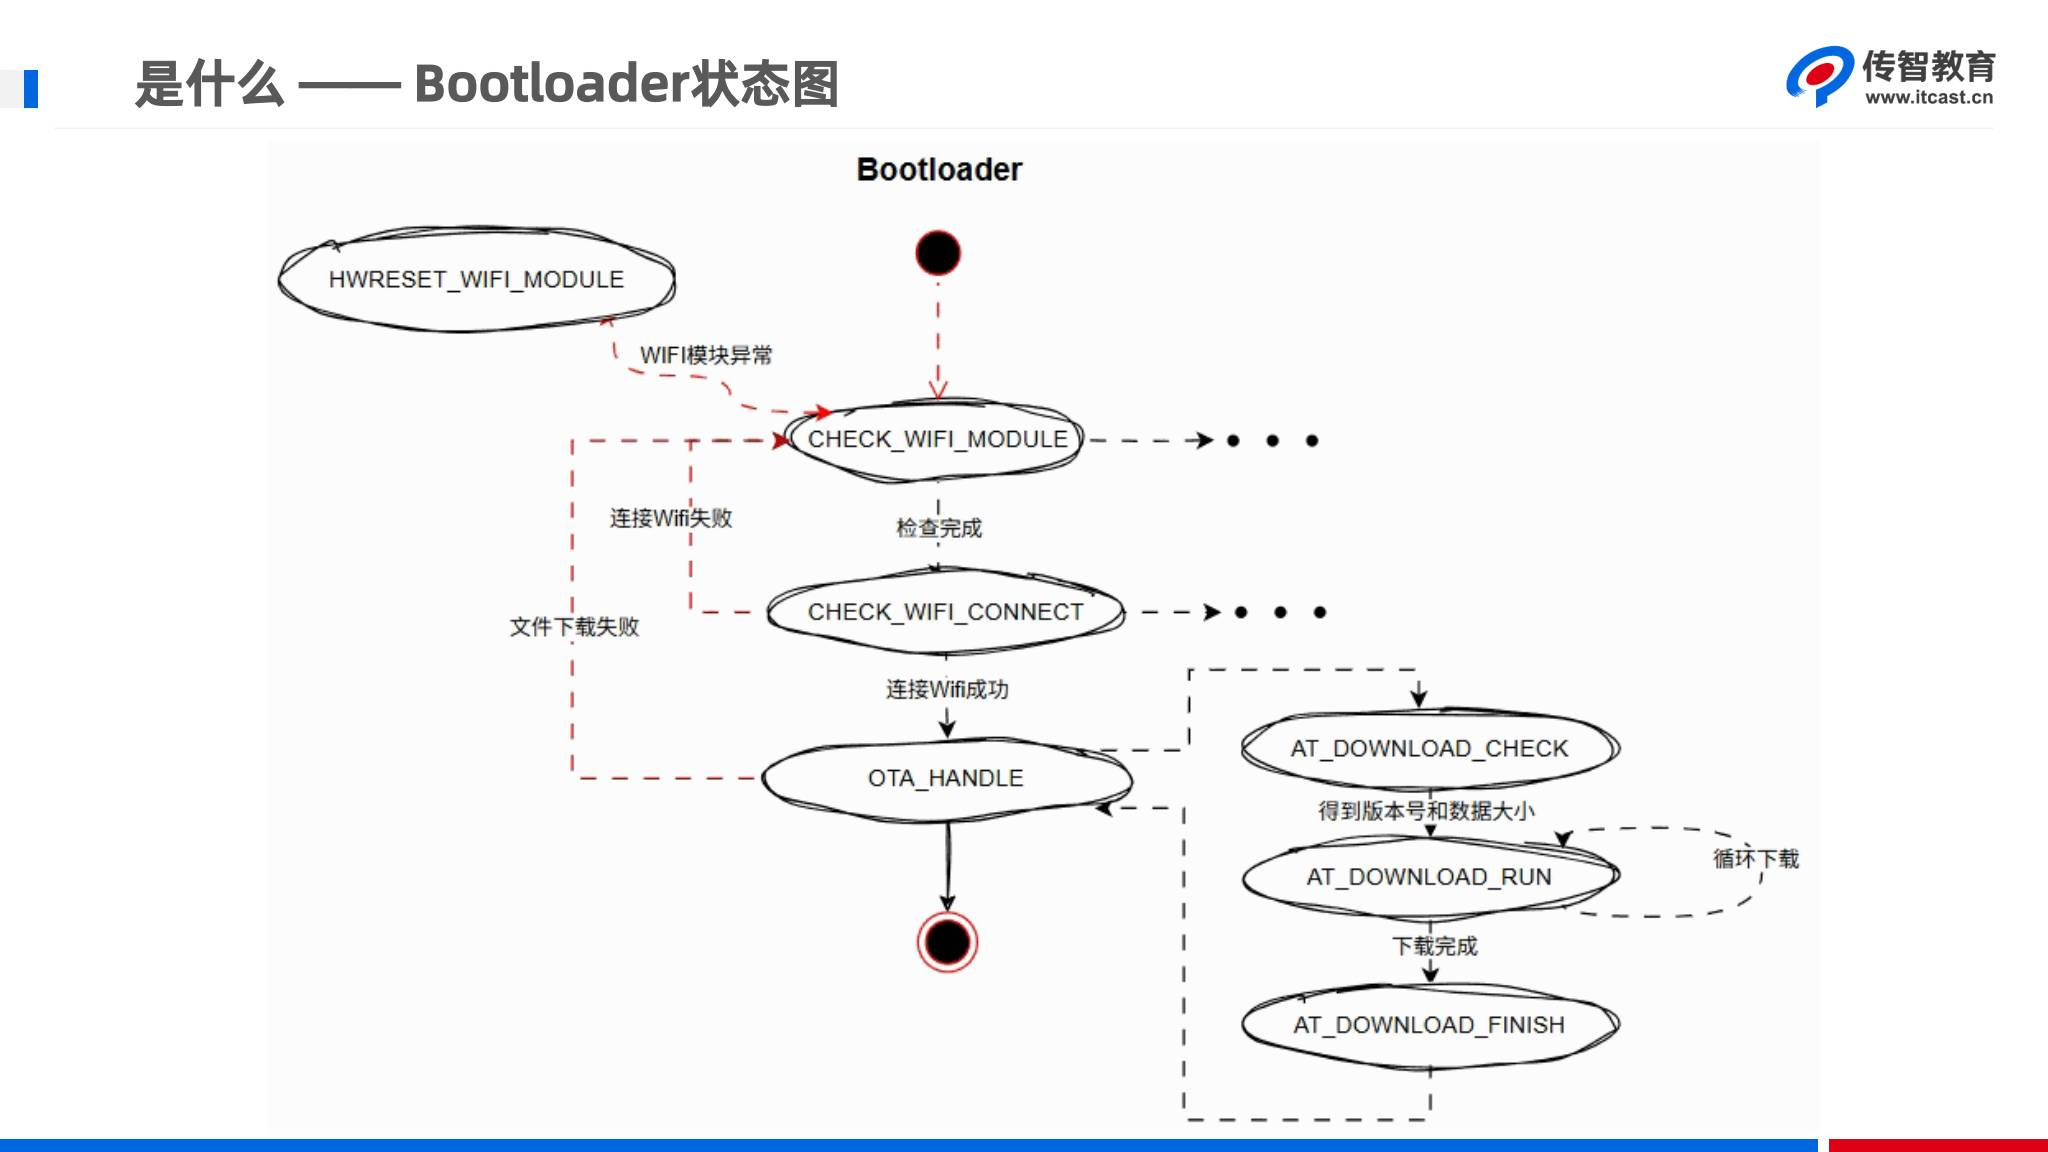

*讲义第73页。左侧是联网主流程，右侧展开OTA下载子流程。*

主状态的函数名是 `OtaDownloadFile()`：

```c
WifiCommState_t OtaDownloadFile(void){ // 2ms间隔调用
    static WifiWorkState_t wifiState = CHECK_WIFI_MODULE;
    WifiCommState_t commState;
    static uint8_t hwresetCount = 0; // 硬件重置Wifi模块计数器

    switch (wifiState) {
        case CHECK_WIFI_MODULE:     // 检查Wifi模块是否存在
            commState = CheckWifiModuleWork();
            if(commState == WIFI_COMM_OK){
                wifiState = CHECK_WIFI_CONNECT;  // 状态切换
            }else if(commState == WIFI_COMM_FAIL){
                wifiState = HWRESET_WIFI_MODULE; // 异常状态切换
            }
            break;
        case CHECK_WIFI_CONNECT:     // 检查Wifi连接状态(如果没连接, 则连接)
            commState = CheckWifiConnect();
            if(commState == WIFI_COMM_OK){
                wifiState = OTA_HANDLE;          // 状态切换
            }else if(commState == WIFI_COMM_FAIL){
                wifiState = CHECK_WIFI_MODULE;   // 异常状态切换
            }
            break;
        case OTA_HANDLE:            // 获取新版本信息
            commState = HandleOTA();
            if(commState == WIFI_COMM_OK){
                wifiState = WIFI_WORK_DONE;     // 状态切换
            }else if(commState == WIFI_COMM_FAIL){
                wifiState = CHECK_WIFI_MODULE;  // 异常状态切换
            }
            break;
        case HWRESET_WIFI_MODULE:               // 硬件重置Wifi模块
            if(hwresetCount < 3){
                printf("HWRESET_WIFI_MODULE\r\n");
                hwresetCount++;
                HwresetWifiModule();
                wifiState = CHECK_WIFI_MODULE;  // 状态切换
            }else{
                wifiState = WIFI_WORK_ERROR;    // 异常状态切换
                hwresetCount = 0; // 重置硬件重置计数器
            }
            break;
        case WIFI_WORK_DONE:
            printf("WIFI_WORK_DONE\r\n");
            return WIFI_COMM_OK;
        
        case WIFI_WORK_ERROR:
            printf("WIFI_WORK_ERROR\r\n");
            return WIFI_COMM_FAIL;
        default:
            break;
    }
    
    return WIFI_COMM_WAIT;
}
```

三条主线：

1. `CHECK_WIFI_MODULE → CHECK_WIFI_CONNECT → OTA_HANDLE` 是正常路径。
2. 模块检查失败进入硬件复位；连网失败或OTA失败回模块检查。
3. 到 `WIFI_WORK_DONE` 才向任务入口返回OK，`WIFI_WORK_ERROR` 返回FAIL。

`HandleOTA()` 进一步展开三个子状态：

```c
typedef enum {
    AT_DOWNLOAD_CHECK = 0,
    AT_DOWNLOAD_RUN,
    AT_DOWNLOAD_FINISH,
} AtDownloadCmdType;
```

| 子状态 | 正常动作 | 什么时候离开 |
| --- | --- | --- |
| CHECK | 请求任务、解析信息、offset归零、擦Backup | 任务解析成功后进RUN |
| RUN | 请求一段、提取字节、写Backup、推进offset | 累计长度达到总大小后进FINISH |
| FINISH | 上报下载完成101 | AT操作终结后向上返回OK |

注意，`WIFI_WORK_DONE` 在这里表示**下载业务结束**，并不是整个OTA升级完成。真正修改App发生在上层 `App_Wifi_Task()` 调用 `OtaFlashFile()` 时。

图中“文件下载失败回检查”也不等于“每种错误最多三次后退出”。网络和OTA分支可以反复回模块检查，硬件复位次数不能限制所有业务循环。


## 5. 工程入口与App侧差异：不要直接把09参数套过来

本篇重点文件：

| 文件 | 作用 |
| --- | --- |
| App/App_Wifi.c | 主状态、三步下载、复制App、引导 |
| Common/utils.c、utils.h | HTTPCLIENT下载包提取、RESP_PREFIX |
| Common/wifi_drv.c、wifi_drv.h | AT发送、WAIT/OK/FAIL、接收块 |
| Common/flash_drv.c、flash_drv.h | 扇区擦除、按字节写入、读取 |
| Common/store_app.c、store_app.h | 参数初始化、版本、升级标志与分区 |
| App/App_OLED.c | 下载百分比与Writing Bin提示 |
| User/tasks.c | OLED 200 ms、按键10 ms、Wi-Fi 2 ms |
| Project/GD32F407.uvprojx | Bootloader目标区、cJSON组件配置 |

硬件仍是USART2/PB10、PB11接ESP AT口，PB12控制EN，115200；USART0负责日志。实际USART2 RX配置是1024字节、DMA0 CH1，不能把驱动里残留的旧硬件描述当初始化依据。

Bootloader与09的App不是逐字一致：

- Bootloader的CWMODE实参为3000 ms，09的App对应位置为1000 ms。
- Bootloader查询AP时等待 `"+CWJAP:\r\n"`，超时3000 ms；09是 `"+CWJAP:"`、1000 ms。通常查询信息在冒号后紧接SSID等字段，前者可能匹配不到，导致已有AP也转主动连接。复现时先看实际完整应答，不要把重复连接误判成Wi-Fi永远没连上。
- Bootloader接收缓冲为 `WIFI_MAX_BUF_SIZE + 1`，拷贝后补NUL；App旧实现不能由此自动获得相同修复。
- Bootloader的JSON函数会Delete解析树，但MD5仍只保存树内指针；这反而引出了悬空指针，见第18节。
- Bootloader检查版本仍使用固定URL参数 `version=1.0`，没有自动使用当前参数版本。

本篇保留这些差异。读课程时应确认工程目录、函数实参和最终源码，不能只按相同函数名推断行为。


## 6. 三条HTTP命令：先代入任务ID，再构造AT字符串

讲义中的AT模板如下：

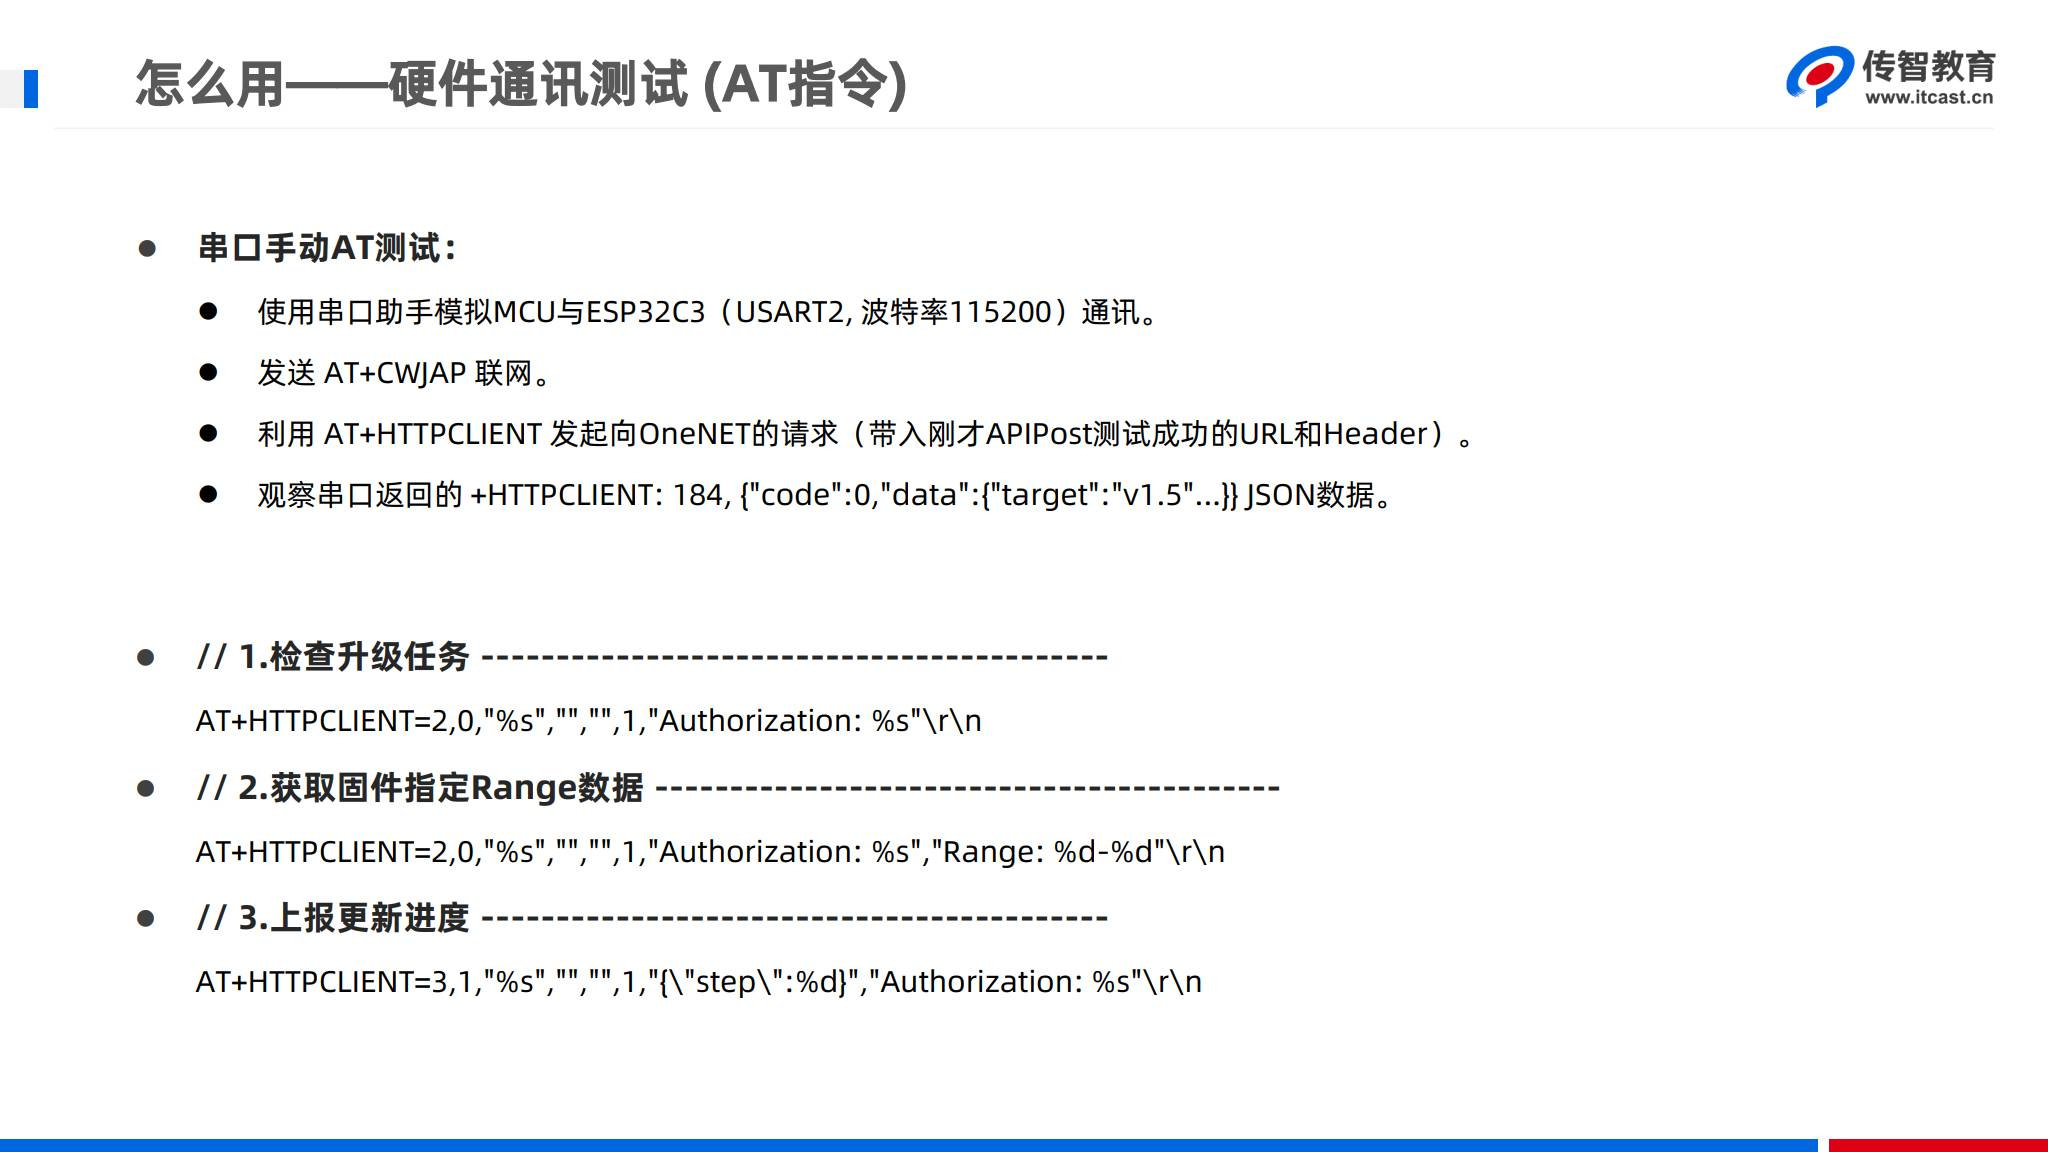

*讲义第69页。HTTP动作由ESP执行，MCU通过串口发送AT文本。*

以下配置来自配套结构，身份和鉴权已替换：

```c
typedef struct {
    char *cmd;
    char *rsp;
    uint32_t timeoutMs;
} AtCmdInfo_t;
#define RESP_PREFIX "+HTTPCLIENT:"

#define PROD_ID     "YOUR_PRODUCT_ID"
#define DEVI_ID     "YOUR_DEVICE_NAME"

// 新版本检查请求链接
const char* g_otaCheckUrl    = "http://iot-api.heclouds.com/fuse-ota/" PROD_ID "/" DEVI_ID "/check?type=1&version=1.0";
// 下载链接
const char* g_otaDownloadUrl = "http://iot-api.heclouds.com/fuse-ota/" PROD_ID "/" DEVI_ID "/%ld/download";
// 上报升级状态
const char* g_otaStatusUrl   = "http://iot-api.heclouds.com/fuse-ota/" PROD_ID "/" DEVI_ID "/%ld/status";
// 请求认证头
const char* g_otaAuthHeader = "YOUR_COMPLETE_TOKEN";

const AtCmdInfo_t g_downloadCmdTable[] = {
    {
        .cmd = "AT+HTTPCLIENT=2,0,\"%s\",\"\",\"\",1,\"Authorization: %s\"\r\n",
        .rsp = RESP_PREFIX, // "OK\r\n"
        .timeoutMs = 3000,
    },
    {
        .cmd = "AT+HTTPCLIENT=2,0,\"%s\",\"\",\"\",1,\"Authorization: %s\",\"Range: %d-%d\"\r\n",
        .rsp = RESP_PREFIX, // "OK\r\n"
        .timeoutMs = 5000,
    },
    {
        .cmd = "AT+HTTPCLIENT=3,1,\"%s\",\"\",\"\",1,\"{\\\"step\\\":%d}\",\"Authorization: %s\"\r\n",
        .rsp = RESP_PREFIX, // "OK\r\n"
        .timeoutMs = 5000,
    }
};
```

数组的三个下标与枚举0、1、2对应。调整枚举顺序时必须同步调整表，不能把RUN读成状态上报命令。

| 命令项 | HTTP动作 | 模板中的变量顺序 | 原超时 |
| --- | --- | --- | --- |
| CHECK | GET任务信息 | check URL、Authorization | 3000 ms |
| RUN | GET固件片段 | download URL、Authorization、start、end | 5000 ms |
| FINISH | POST状态JSON | status URL、step、Authorization | 5000 ms |

`g_otaDownloadUrl` 和 `g_otaStatusUrl` 中有 `%ld`，它们只是**带占位符的路径模板**。正确做法是：

```c
/* 原代码思路：先生成带真实tid的URL，再生成AT命令 */
sprintf(urlStr, g_otaDownloadUrl, g_otaTaskId);
sprintf(cmdStrBuf, info.cmd, urlStr, g_otaAuthHeader,
        range_start, range_start + RANGE_SIZE - 1);
```

`sprintf` 对外层格式串执行一轮格式化，**不会递归处理被%s插入字符串里的%ld**。这是视频43出现400 Bad Request的关键原因，后面专门复盘。

原模板把 `uint32_t` 值配给 `%ld/%d`。常见32位ABI上位宽可能相同，但可变参数仍应按真实类型匹配。补充改进可使用 `<inttypes.h>` 的 `PRIu32`，或在确认范围后使用与格式对应的显式转换；也要用 `snprintf` 检查128/256字节数组是否截断。

原课程使用HTTP和transport_type=1。若改HTTPS，需要一起核对ESP-AT的TLS传输设置，不能仅替换URL前缀。


## 7. HandleOTA完整原实现：三步连成一个轮询子流程

下面保留配套Bootloader的完整函数，便于对照后面的解释。原二进制示例注释里的控制字节用字面量转义显示，便于阅读。它包含课堂简化处理，**并非经过完整边界和故障验证的安装器**。

```c
#define RANGE_SIZE 512
static uint32_t range_start = 0;
static uint8_t dataBuf[1024] = {0};

WifiCommState_t HandleOTA(void){
    static AtDownloadCmdType cmdType = AT_DOWNLOAD_CHECK;
    WifiCommState_t commState = WIFI_COMM_WAIT;
    static uint8_t retryCount = 0;
    AtCmdInfo_t info;
    char cmdStrBuf[256];
    switch (cmdType) {
        case AT_DOWNLOAD_CHECK:
            // 清理旧的数据缓存
            memset(g_recvStrBuf, 0, WIFI_MAX_BUF_SIZE);

            info = g_downloadCmdTable[AT_DOWNLOAD_CHECK];
            sprintf(cmdStrBuf, info.cmd, g_otaCheckUrl, g_otaAuthHeader);
            commState = AtCmdHandle(cmdStrBuf, info.rsp, info.timeoutMs);
            if(commState == WIFI_COMM_OK){
//                printf("HandleOTA[%d]->%s\r\n", g_pktRcvdLen, g_recvStrBuf);
                int8_t err = parse_json_data(g_recvStrBuf);
                if(err != 0){
                    return WIFI_COMM_FAIL;
                }

                range_start = 0;
                // 清理要写入的目标区域1111111111111111111111111111111111
                FlashErase(BACKUP_ADDR_IN_FLASH, g_otaBinSize);

                // 解析成功, 切换到下载状态
                cmdType = AT_DOWNLOAD_RUN;
                // return WIFI_COMM_OK;
            }else if(commState == WIFI_COMM_FAIL){
                RETRY(AT_DOWNLOAD_CHECK);
            }
            break;
        case AT_DOWNLOAD_RUN:
            info = g_downloadCmdTable[AT_DOWNLOAD_RUN]; // range_start, range_start + RANGE_SIZE - 1
            // 将任务id格式化到g_otaDownloadUrl
            char urlStr[128] = "";
            sprintf(urlStr, g_otaDownloadUrl, g_otaTaskId);
            // 将请求url, auth header, range格式化到cmdStrBuf
            sprintf(cmdStrBuf, info.cmd, urlStr, g_otaAuthHeader, range_start, range_start + RANGE_SIZE - 1);
            commState = AtCmdHandle(cmdStrBuf, info.rsp, info.timeoutMs);
            if(commState == WIFI_COMM_OK){
                printf("Download Range %d -> %d\r\n", range_start, range_start + RANGE_SIZE - 1);
                // 提取数据长度和字节数组到len和dataBuf ==>  +HTTPCLIENT:100,X\x1A\0 澚\0\x08奢\0\x08
                uint16_t len = parse_download_pack(g_recvStrBuf, g_pktRcvdLen, dataBuf);
                if(len == 0){
                    return WIFI_COMM_FAIL;
                }

                // 写入数据到备份区 2222222222222222222222222222222222
                FlashWrite(BACKUP_ADDR_IN_FLASH + range_start, dataBuf, len);

                printf("Write %d bytes to Backup Flash\r\n", len);
                // 更新下载开始字节位置
                range_start += len;
                if(range_start >= g_otaBinSize){
                    printf("Download Finish: %d bytes\r\n", range_start);
                    cmdType = AT_DOWNLOAD_FINISH;
                }

            }else if(commState == WIFI_COMM_FAIL){
                RETRY(AT_DOWNLOAD_CHECK);
            }
            break;
        case AT_DOWNLOAD_FINISH:{
            printf("下载完成, 上报下载完成情况!\r\n");
            info = g_downloadCmdTable[AT_DOWNLOAD_FINISH];
            // 将任务id格式化到 g_otaStatusUrl
            char urlStr[128] = "";
            sprintf(urlStr, g_otaStatusUrl, g_otaTaskId);
            // 将请求url, auth header, step格式化到cmdStrBuf
            sprintf(cmdStrBuf, info.cmd, urlStr, 101, g_otaAuthHeader);
            commState = AtCmdHandle(cmdStrBuf, info.rsp, info.timeoutMs);
            if(commState == WIFI_COMM_OK){
                printf("上报下载进度完成\r\n");
                // 切换到下载状态
                cmdType = AT_DOWNLOAD_RUN;
                return WIFI_COMM_OK;
            }else if(commState == WIFI_COMM_FAIL){
                cmdType = AT_DOWNLOAD_RUN;
                return WIFI_COMM_OK;
            }
            break;
        }
        default: 
            break;
    }

    return WIFI_COMM_WAIT;
}
```

通读时抓住五个动作：

1. CHECK成功时清零偏移并擦Backup，随后切换RUN，**不立即返回OK**。
2. RUN每次只处理一段；本段写完仍留在RUN，下轮继续请求。
3. 偏移增加实际 `len`，不是固定增加512。
4. 累计完成后先进入FINISH，上报101。
5. FINISH在WAIT时留在本状态，只有AT成功或超时结束才返回OK。

需要保留但不能忽略的原码边界：未验证下载size上限，未检查FlashErase/FlashWrite的bool，包解析缺少容量与完整性检查；FINISH只按前缀匹配，不解析业务code；FINISH结束后还把cmdType设为RUN。后者在本轮成功后立即安装/跳转的课堂路径中不继续运行，但若复用为周期任务，会带着旧offset继续RUN。应在重新进入流程时显式重置上下文。


## 8. CHECK阶段：先验证任务，再擦除暂存区

原成功分支的核心顺序：

```c
int8_t err = parse_json_data(g_recvStrBuf);
if (err != 0) {
    return WIFI_COMM_FAIL;
}
range_start = 0;
FlashErase(BACKUP_ADDR_IN_FLASH, g_otaBinSize);
cmdType = AT_DOWNLOAD_RUN;
```

Bootloader重新查询任务，不能依赖App复位前的RAM变量、JSON树或MD5地址。App只传递了参数区升级请求标志。

进入RUN前至少应确认：

- 返回JSON完整、业务 `code=0`、data对象和所需字段有效。
- `tid`、`size` 都是合法整数；`size`不为0、不超过App容量。
- 目标包为当前安装器支持的完整包；差分包不能直接当App写入。
- 版本、MD5文本复制到自身缓冲，释放cJSON后仍可使用。
- 擦除范围符合Backup分区，擦除结果成功。

原 `parse_json_data()` 虽打印code/msg，**Bootloader这份代码没有用非零code提前拒绝任务**。视频46最后补充了非零code的检查，但提供的Bootloader源码未同步该逻辑。应把它视为视频补丁和源码快照差异，不能声称原函数已经完整校验业务结果；非零code也不能一概解释成“没有升级包”。

CHECK分支每次调用都会 `memset(g_recvStrBuf,0,WIFI_MAX_BUF_SIZE)`。这有助于减少旧显示残留，但没有清空底层待接收标志、没有做事务配对，也没有把跨回调的半包累积起来。清零旧缓冲不能替代消息边界处理。

擦Backup时还要注意 `FlashErase` 的结束地址算法。本篇第20节会结合App擦除详细说明；不能照抄 `FlashErase(addr,size)` 后就认为它严格只擦size字节。


## 9. Range计算：512字节、末段400字节与偏移不变量

配套 `RANGE_SIZE=512`，请求的起止位置都包含在范围内：

```text
第1次：start = 0      end = 0 + 512 - 1 = 511
第2次：start = 512    end = 1023
第3次：start = 1024   end = 1535
……
每次成功写入len字节后：start += len
```

本课OneNET接口文档定义的请求头是 `Range: start-end`；这里按该接口约定使用，不能把所有HTTP服务的Range格式都推断成一样。通用HTTP字节范围常见 `bytes=` 单位前缀，移植时需核对目标服务。

以课程的32656字节镜像为例：

| 项目 | 数值 |
| --- | --- |
| 63个完整片段 | 63 × 512 = 32256字节 |
| 最后一个片段 | 32656 − 32256 = 400字节 |
| 最后请求，按原码 | 32256—32767 |
| 最后实际返回 | 32256—32655，共400字节 |
| 总片段数 | 64 |
| 最终偏移 | 32656，恰好等于总大小 |

官方文档说明end超过文件长度时会截到len−1，因此课堂原码的最后一个512字节范围能收到较短末段。**这是这个接口的规则，不能依赖所有服务器都帮忙截断。**

补充改进可先计算有效请求长度：

```c
/* 前提：0 < total <= APP_SIZE，offset < total */
uint32_t remain = total - offset;
uint32_t request_len = remain < RANGE_SIZE ? remain : RANGE_SIZE;
uint32_t end = offset + request_len - 1;
```

每次接受片段时应维持：

```text
0 <= offset < total
实际返回长度 == 本次期望片段长度
写入地址 = BACKUP_ADDR_IN_FLASH + offset
写入成功后才：offset += actual_len
最终完成条件：offset == total
```

原实现用 `range_start >= g_otaBinSize` 结束。如果误把超长或错误响应也计入偏移，>=可能掩盖多写；不能把“超过了”当完整性证明。失败重试同一段时，offset不能提前移动，也不能把同一片段重复追加到下一地址。

这套流程从0重新下载，没有持久化已下载offset和分片有效性，不是跨复位断点续传。


## 10. 视频43的400排错：外层sprintf不会替换URL里的%ld

课堂最初构造的命令虽然填了产品名、设备名和Range，download URL里还残留 `%ld`，导致请求错误。

错误形态：

```text
http://iot-api.heclouds.com/fuse-ota/<product>/<device>/%ld/download
```

即便对这个字符串执行：

```c
sprintf(cmdStrBuf, info.cmd, g_otaDownloadUrl, token, start, end);
```

外层 `%s` 也只会原样插入URL文本，不会再解释其中 `%ld`。修复是“两次格式化”：

```c
char urlStr[128] = "";
sprintf(urlStr, g_otaDownloadUrl, g_otaTaskId);
sprintf(cmdStrBuf, info.cmd, urlStr, g_otaAuthHeader,
        range_start, range_start + RANGE_SIZE - 1);
```

视频用另一块独立ESP和串口工具对比“手工可用命令”与“程序命令”，发现任务ID占位符没有替换；修正后才正常连续下载。第二块板是调试手段，不是OTA系统运行的必要条件。

复现时按层比较：协议与域名、产品、设备、任务ID、路径、Authorization、Range、AT引号与结尾CRLF。把脱敏后的完整命令保存在本地对比，比同时改网络、Flash和JSON函数更容易定位。

状态上报也需要同样先格式化 `/{tid}/status`。格式化成功还要检查返回长度，不能因为字符串能打印就认定没有越界。


## 11. 下载二进制：长度为准，printf只用于看头部

AT响应大致是：

```text
+HTTPCLIENT:<payload长度>,<原始固件字节>
……
OK
```

固件payload不是十六进制字符文本。出现 `00`、逗号、CRLF甚至与前缀相同的字节序列都可能合法。接收时应分离“ASCII包头”和“指定长度的二进制payload”。

```c
/* 合法固件片段可能是这6个原始字节 */
uint8_t sample[] = {0x00, 0xFF, 0x2C, 0x0D, 0x0A, 0x7F};
```

`strlen(sample)` 不能给出长度；`printf("%s",...)` 遇到第一个NUL就停止，也可能显示乱码。**日志只显示半段，并不能证明DMA实际只收到半段。** 应查看真实接收计数和按长度输出的十六进制数据。

Bootloader的接收函数与09的App不同：

```c
uint16_t RecvWifiModuleStr(char *buffer)
{
    if (g_pktRcved)
    {
        g_pktRcved = false;
        memcpy(buffer, g_recvDataBuf, g_pktLen);
        buffer[g_pktLen] = '\0';
        printf("uart2 recv->%s\r\n", buffer);
        memset(g_recvDataBuf, 0, WIFI_MAX_BUF_SIZE);
        return g_pktLen;
    }
    return 0;
}
```

它确实会补NUL，并保留 `g_pktRcvdLen`，但仍有边界：

- 必须保证 `g_pktLen <= WIFI_MAX_BUF_SIZE`，否则拷贝和终止符写入都可能越界。
- 底层共享缓冲在主循环中拷贝、清零；如果DMA/中断已经开始复用该内存，仍有所有权竞争。
- 单个指针/长度/标志不等于接收队列，连续回调可能覆盖尚未消费的数据。
- `AtCmdHandle` 用strstr找ASCII前缀；前缀前若有NUL、或前缀跨块，就可能匹配失败。
- 看见前缀不代表payload已经全到。原驱动未提供完整串口流重组。

视频44尝试把下载块改为1024，视频45遇到异常后退回512。源码的接收底层为1024字节；但**1024字节payload不等于1024字节整帧**：

| payload | ASCII头长度 | 头+payload | 再加“CRLF OK CRLF”示意 |
| --- | --- | --- | --- |
| 512 | 16 | 528 | 534 |
| 1024 | 17 | 1041 | 1047 |

响应可能被拆成多个HTTPCLIENT记录或串口接收块，实际尾部也取决于固件；上表只是容量下限示意。仅把 `dataBuf` 扩成1024，不能解决DMA整帧容量、分段累积和解析条件。课堂退回512可解释为这套接收链路的限制，不能推广成ESP或HTTP协议最多只能收512。


## 12. 原parse_download_pack：dataLen参数没有被使用

原工具函数很短：

```c
uint16_t parse_download_pack(char* inBuf, uint32_t dataLen, uint8_t* outBuf) {
    uint16_t total_len = 0;

    // 查找第一个 +HTTPCLIENT:%hu, 将数字格式化到total_len
    sscanf(inBuf, RESP_PREFIX "%hu,", &total_len);

    // 找第一个逗号
    char* p_comma = strchr(inBuf, ',');
    if(p_comma == NULL) {
        printf("Failed to find comma.\n");
        return 0;
    }
    p_comma++; // 跳过逗号

    // 将p_comma的total_len个数据, 复制到outBuf
    memcpy(outBuf, p_comma, total_len);
    return total_len;
}
```

它做了三件事：从开头读长度、找第一个逗号、按长度memcpy。这样能解释课堂一次收到一个完整小包时为何可用，但存在明确前提：

| 原实现 | 潜在问题 |
| --- | --- |
| sscanf从inBuf开头匹配 | 若前面多了CRLF、日志或其他响应，长度读取失败 |
| 没有检查sscanf返回值 | 长度未成功解析仍继续找逗号 |
| 不使用dataLen | 无法判断当前接收是否包含全部payload |
| 不传outBuf容量 | total_len过大可能写穿目标缓冲 |
| uint16_t长度 | 需要检查数字是否超出可表示范围 |
| 只找第一个逗号 | 未严格验证逗号一定属于目标包头 |
| 只处理一个记录 | 一次响应拆成多个HTTPCLIENT记录时不能完整合并 |

若声明512字节但本次只收到100字节，这个函数仍会从逗号后复制512字节，可能把后面的旧数据一并写入Flash。它不能仅靠“len非零”证明数据完整。

同文件另有 `parse_download_data()` 尝试遍历多个前缀，但 `HandleOTA()` 实际调用的是 `parse_download_pack()`。不能因为另一个函数存在，就说主流程已经支持多包重组；后者同样需要容量、二进制边界和跨回调累积检查。


## 13. 补充改进：带容量的单记录二进制解析

下面是独立学习片段，展示“按接收长度检查”的思路，**未接入课程工程、未目标编译**。输入约定：缓冲从一个 `+HTTPCLIENT:` 开始，头部前已由接收状态机完成定位；本函数只解析一个记录，不负责命令配对、UART环形缓冲或整个HTTP响应拼接。

```c
#include <stdint.h>
#include <stddef.h>
#include <string.h>

typedef enum {
    PACK_MORE,   /* 还未收到足够字节 */
    PACK_OK,
    PACK_BAD
} PackResult;

static PackResult ParseHttpClientRecord(
    const uint8_t *in, size_t in_len,
    uint8_t *out, size_t out_cap,
    size_t *payload_len, size_t *consumed)
{
    static const char prefix[] = "+HTTPCLIENT:";
    const size_t prefix_len = sizeof(prefix) - 1;
    size_t i, count = 0, digits = 0, common;

    if (!in || !out || !payload_len || !consumed) return PACK_BAD;
    *payload_len = 0;
    *consumed = 0;

    common = in_len < prefix_len ? in_len : prefix_len;
    if (memcmp(in, prefix, common) != 0) return PACK_BAD;
    if (in_len < prefix_len) return PACK_MORE;

    i = prefix_len;
    while (i < in_len && in[i] >= '0' && in[i] <= '9') {
        size_t d = (size_t)(in[i] - '0');
        /* 先验证乘10、加d不会超出目标容量 */
        if (d > out_cap || count > (out_cap - d) / 10)
            return PACK_BAD;
        count = count * 10 + d;
        ++i;
        if (++digits > 10) return PACK_BAD;
    }

    if (i == in_len) return PACK_MORE;
    if (digits == 0 || in[i] != ',' || count == 0) return PACK_BAD;
    ++i;
    if (count > in_len - i) return PACK_MORE;

    memcpy(out, in + i, count); /* 复制原始二进制，不用strlen */
    *payload_len = count;
    *consumed = i + count;
    return PACK_OK;
}
```

调用层还要做的事：

1. PACK_MORE保留已有数据，等待新字节，设置整帧超时与累计容量上限。
2. PACK_OK按consumed消费已处理字节，继续处理尾部OK或后续记录；payload可能含任意字节，不能在其内部搜索前缀。
3. PACK_BAD使当前事务失败并明确恢复规则，不把可疑数据写Flash。
4. 若一个Range响应包含多个记录，需要累加到本次期望的request_len，再确认HTTP/AT终态。
5. 在HTTP接口能提供的情况下核对状态、Content-Range和Content-Length，排除把错误正文当固件的情况。

本函数的out与输入应是独立缓冲，且out_cap应是真实分配容量。它只改善单记录提取，不能被描述成完整、可直接部署的ESP-AT二进制接收驱动。


## 14. 写Backup与重试：写成功之后才推进offset

课堂RUN分支按下列顺序写入：

```c
uint16_t len = parse_download_pack(g_recvStrBuf, g_pktRcvdLen, dataBuf);
if (len == 0) {
    return WIFI_COMM_FAIL;
}
FlashWrite(BACKUP_ADDR_IN_FLASH + range_start, dataBuf, len);
range_start += len;
```

核心地址关系正确：**基址不变，偏移移动**。若始终写 `BACKUP_ADDR_IN_FLASH`，每段会覆盖开头；若offset在写前就增加，会漏掉最初一段或把失败片段当成功。

但原码忽略FlashWrite返回值，打印 `Write ... bytes` 只是执行到了日志，不能证明写入成功。补充片段应在输入已经完整验证后检查：

```c
/* 示例：已保证range_start < g_otaBinSize、dataBuf装得下 */
uint32_t remain = g_otaBinSize - range_start;
uint32_t expected = remain < RANGE_SIZE ? remain : RANGE_SIZE;

if (len != expected) {
    return WIFI_COMM_FAIL;
}
if (!FlashWrite(BACKUP_ADDR_IN_FLASH + range_start, dataBuf, len)) {
    return WIFI_COMM_FAIL;
}
range_start += len;
if (range_start == g_otaBinSize) {
    cmdType = AT_DOWNLOAD_FINISH;
}
```

这是局部示意；与原静态状态合并时要同时重置子状态、计数、AT事务和暂存区有效性。特别是原函数parse返回0时直接FAIL，却没有把cmdType从RUN退回CHECK；外层联网后再次调用可能还在RUN，**并非每个失败都会从头擦除重下**。

原RETRY宏依赖当前函数里的retryCount和cmdType，达到3次累计失败时直接返回当前函数：

```c
#define RETRY(fallback_cmdType)           \
    do {                                \
        if (++retryCount >= 3) {        \
            cmdType = fallback_cmdType; \
            retryCount = 0;             \
            return WIFI_COMM_FAIL;      \
        }                               \
    } while (0)
```

成功分支没有普遍清零retryCount，所以跨片段成功后仍可能保留失败次数。应明确设计“同一片段连续失败次数”或“整次下载总失败次数”，不能把课堂残留计数解释成已有完善策略。

网络失败重发同一请求通常可行；Flash失败后是否能直接同地址重写则依赖实际写入结果和Flash编程规则，不能不检查就反复写。重新开始下载前重新擦除目标扇区，才有明确的初始状态。


## 15. OLED百分比：本地显示不等于云端进度

配套进度函数：

```c
uint8_t App_Wifi_GetUpdateProgress(void){
    uint8_t progress = range_start * 100 / g_otaBinSize; // [0, 100]
    if(progress >= 100) progress = 100;
    return progress;    
}
```

在有效下载且 `g_otaBinSize>0` 时，先乘100再整除，能得到整数百分比。若先做 `range_start / g_otaBinSize`，大部分下载期间都为0。

边界说明：

- 总大小为0时存在除零风险；课堂OLED先通过GetNewVersion检查非零大小，当前调用路径可绕开，但进度函数自身不安全。
- `range_start * 100` 可能在通用大文件场景溢出；严格限制208 KiB时不会。
- 原结果先存入uint8_t再检查>=100，不能用这种顺序处理任意超大偏移。
- 更稳妥的计算先判total=0，再在宽整数中计算并限幅。

补充片段：

```c
static uint8_t DownloadPercent(uint32_t done, uint32_t total)
{
    if (total == 0) return 0;
    if (done >= total) return 100;
    return (uint8_t)(((uint64_t)done * 100u) / total);
}
```

OLED每200 ms刷新 `->Downloading: xx%`；原代码在 `progress >= 98` 显示 `->Writing Bin`。**这个提示是进度阈值，不是真正的安装状态**：98%时仍可能下载，复制时又会阻塞主循环。因此屏幕出现Writing Bin不能代替Flash写入结果。

FINISH才发一次101，原代码没有把每个本地百分比都上报服务器。视频提到当时控制台仅显示待升级、下载中、升级中等状态，这是课堂当时的页面观察，不代表协议不支持0—100进度。


## 16. 上报101：下载完成，只发100或101其中一个

按OneNET接口定义：

| step | 含义 | 设备侧应该何时产生 |
| --- | --- | --- |
| 0—99 | 下载进度 | 处于可上报下载进度的状态时 |
| 100 | 下载100%，平台转升级中 | 下载完成，可与101二选一 |
| 101 | 升级包下载成功，转升级中 | 本次选择的下载完成报告 |
| 104 | 下载请求超时失败 | 根据实际终止原因分类 |
| 201 | 升级成功，平台版本更新为任务目标版本 | 安装成功的适当确认点 |
| 205 | MD5校验失败 | 实际执行校验且失败时 |
| 206 | 升级失败、未知异常 | 按平台状态和实际故障使用 |
| 207 | 达到最大重试次数 | 明确达到策略上限时 |

**100与101都表示下载完成，不应先报100，再重复报101。** 官方文档对状态有约束，已经进入升级中、成功、取消等状态后，允许的请求不同；不能把状态接口当作任意可重复写的普通数字字段。

课程使用如下内容：

```json
{"step":101}
```

AT字符串涉及两层转义：

```c
/* C源代码中的AT模板 */
"AT+HTTPCLIENT=3,1,\"%s\",\"\",\"\",1,"
"\"{\\\"step\\\":%d}\",\"Authorization: %s\"\r\n"
```

```text
串口可见形式（示意）：
AT+HTTPCLIENT=3,1,"<status-url>","","",1,"{\"step\":101}","Authorization: <token>"
```

C的转义用于构造串口字节；AT参数中的转义再由ESP解释为JSON。不要把字面量里的反斜线层数直接当HTTP正文。

FINISH成功或超时都返回WIFI_COMM_OK，是课程的策略：**101上报失败不取消已完成的本地下载**。但这个OK不能解释成“云端已确认下载成功”，并且原判据只是 `+HTTPCLIENT:`，没解析状态响应中的code。若要确认云端结果，需要完整读取响应并验证 `code=0`。

同名 `urlStr` 在不同case中声明时，要注意switch各case默认共用外层作用域。视频44通过 `case ...: { ... }` 建立独立块，避免重定义；也可以在switch外声明后赋值。


## 17. 视频46：为什么201命令可能根本没发出去

`AtCmdHandle()` 的状态是函数内static，所有命令共享一个在途事务：

```c
/* 简化展示原驱动的关键门槛 */
if (s_commState != WIFI_COMM_WAIT) {
    SendWifiModuleStr(cmd);
    s_sendCmdTime = systick_get_tick();
    s_commState = WIFI_COMM_WAIT;
    return WIFI_COMM_WAIT;
}
/* WAIT分支只处理原事务的超时和响应，不会发送新cmd */
```

最初课堂为了走通流程，在刚调用101发送后就直接返回OK，进入复制和201上报。结果：

```text
101第一次调用：真正发送，驱动进入WAIT
        ↓
上层过早认定结束，跳去OtaFlashFile
        ↓
201调用AtCmdHandle：驱动仍是WAIT
        ↓
只检查旧101响应/超时，没有执行SendWifiModuleStr(201)
        ↓
App启动了，云端却一直是“升级中”
```

**仅仅调用过AtCmdHandle(201)不等于发送过201。** 这也是视频中最后没有看到对应发送日志的解释。

视频46修正两处：

1. 在101 FINISH阶段，WAIT继续停留；等AT返回OK或FAIL，驱动离开WAIT后，上层才离开下载流程。
2. 201发送后延时2000 ms，再启动App，减少App初始化硬复位ESP时打断尚未完成网络操作的机会。

配套源码已包含这两处修改。101 WAIT时不要立即返回成功；每2 ms回到同一状态检查，不会在WAIT期间重复发送同一命令。

还要区分两层问题：等待101事务终结，解决的是**201能否开始发送**；201后延时，只是经验等待，**仍没有实际确认201响应和业务code**。2秒不是网络必达保证，也不是通用协议规定。


## 18. MD5与镜像有效性：取得字段不代表做过校验

视频42提到校验通过后才覆盖App；视频43明确暂不做校验，先走下载与烧录。源码核对结果也一致：保存了MD5字段，但**没有对Backup固件计算MD5并与云端目标比对的调用**。

更要注意Bootloader这份解析器的顺序：

```c
g_targetMD5 = md5->valuestring;
cJSON_Delete(root);
```

`g_targetMD5` 借用cJSON树中的内存，Delete后就悬空。09的App原解析器没有正常释放树，是泄漏；Bootloader这里则是释放后仍保留借用地址。不能把两份函数的缺陷混成同一个现象。

若要补上校验，需要先把MD5复制到独立33字节数组，再释放JSON；验证它为32位十六进制文本。随后**从Backup读回实际写入的size字节**计算MD5，与目标值一致才允许擦App。只校验接收缓冲不能发现Flash写入错误；安装后还应验证App目标区。

本地样本核对可用来理解“文件名不等于摘要”：

| 配套文件 | 实际大小 | 本地计算MD5 |
| --- | --- | --- |
| OTA_v1.6.bin | 32656 | 988e516070c2143059fdd367a573c510 |
| OTA_v2.0.bin | 32696 | 6c7ba89df0fcfff75e17de94c3e05ee3 |

这些值是本次对 `06_GD32F407_OTA_App/Versions` 里的文件静态计算所得。源码注释中另有一份示例JSON，其MD5/大小与上述文件不一致，不能拿注释或网盘文件标识当当前任务的真实摘要。

补充说明：MD5可用于检测传输、存储中意外损坏，不能承担可信发布者认证。工程化升级还需可信元数据、签名及版本/硬件约束。课程没有实现签名、差分重建和防降级，不应在笔记中把这些描述成现成功能。

本篇只解释正确校验位置，没有替原工程加入MD5库或伪造“已通过硬件校验”的结论。


## 19. OtaFlashFile完整原码：把Backup搬到App

原函数在主循环任务回调内同步执行：

```c
uint8_t g_flashReadBuf[FLASH_PAGE_SIZE];

void OtaFlashFile(){
    printf("将Backup区域数据写入到App区\r\n");

    printf("1. 清理App区数据\r\n");
    FlashErase(APP_ADDR_IN_FLASH, APP_SIZE - 1);

    printf("2. 循环写入新固件到App区\r\n");
    int32_t totalSize = g_otaBinSize;
    uint32_t offset = 0;
    while(totalSize > 0){
        // 读取Backup数据
        FlashRead(BACKUP_ADDR_IN_FLASH + offset, g_flashReadBuf, FLASH_PAGE_SIZE);
        print_arr(g_flashReadBuf, FLASH_PAGE_SIZE);

        // 写入App区
        FlashWrite(APP_ADDR_IN_FLASH + offset, g_flashReadBuf, FLASH_PAGE_SIZE);
 
        offset += FLASH_PAGE_SIZE;
        totalSize -= FLASH_PAGE_SIZE;

        printf("Write totalSize -> %d bytes\r\n", totalSize);
    }
    
    printf("3. 上报Flash烧录成功消息(升级成功201)\r\n");
    char urlStrBuf[128] = "";
    char cmdStrBuf[256] = "";
    AtCmdInfo_t cmdInfo = g_downloadCmdTable[AT_DOWNLOAD_FINISH];
    sprintf(urlStrBuf, g_otaStatusUrl, g_otaTaskId);
    // 格式化命令
    sprintf(cmdStrBuf, cmdInfo.cmd, urlStrBuf, 201, g_otaAuthHeader);
    AtCmdHandle(cmdStrBuf, cmdInfo.rsp, cmdInfo.timeoutMs);
    
    // 等待2000ms, 保证"升级成功"消息发送完毕
    DelayNms(2000);
    
    printf("4. 上报完成\r\n");
}
```

流程是：

```text
擦App全部预留区域
  → 从Backup按1 KiB读
  → 逐块写App
  → 构造201上报
  → 调用一次AtCmdHandle
  → 延时2000 ms
  → 返回上层保存版本、清标志
```

原 `totalSize` 使用有符号int32_t，最后不足1 KiB时减1024会变负数，从while退出，避免无符号减法下溢后继续循环。但它仍会按整块读写末段。

32656字节的固件按1 KiB复制：

```text
31 × 1024 = 31744
余下       =   912
原实现复制32块 = 32768字节
超出镜像末尾   =   112字节
最后totalSize   =  -112
```

课程解释后面的字节通常为擦除态FF，在当前布局和已擦暂存区内可能无碍；但**未检查读写结果、未验证镜像大小、未限制对齐后范围时，不能笼统说多拷一点总是安全**。固定大小缓冲与真实Flash擦除单元也不同，第20节展开。

打印 `print_arr` 以十六进制按长度输出，比%s适合看固件；但不是校验，数据“不是全FF”也不证明它就是完整可执行App。大量逐字节打印会显著延长复制阶段，影响调度和看门狗。


## 20. 擦除边界与末块：APP_SIZE−1是为适配这个驱动

原函数：

```c
FlashErase(APP_ADDR_IN_FLASH, APP_SIZE - 1);
```

这里减1有具体原因。配套 `FlashErase` 采用：

```c
start_sector_info = fmc_sector_info_get(eraseAddr);
end_sector_info = fmc_sector_info_get(eraseAddr + numToErase);
/* 从起始扇区到结束扇区，均包含 */
```

它把 `eraseAddr + numToErase` 当作包含式末地址来选扇区，而通常“长度n”应对应末地址 `addr+n−1`。若App起点0x0800C000加APP_SIZE，结果是 **0x08040000，正好是Backup起点**；不减1就可能多擦Backup的第一个扇区，毁掉刚下载的镜像。

| 调用 | 算出的结束地址 | 结果 |
| --- | --- | --- |
| FlashErase(APP_ADDR, APP_SIZE) | 0x08040000 | 可能连Backup首扇区一起擦 |
| 原码减1 | 0x0803FFFF | 停在App末扇区 |
| 规范长度API应采用 | addr + length − 1 | 需同时修正全工程调用约定 |

这不是“所有擦除长度都减1更保险”的通用原则，而是适配当前封装的边界。读改驱动时还要检查零长度、溢出、Flash首尾地址和扇区范围。原FlashRead/Write的末地址检查也存在排除最后一个字节的边界问题，不能单靠驱动现有判断充当分区保护。

Backup擦除同理，若 `g_otaBinSize` 恰落扇区边界，原代码也可能多选一个扇区。应按明确的半开区间 `[addr,addr+length)` 设计统一API，而不是各处临时猜减1。

`store_app.h` 的 `FLASH_PAGE_SIZE=0x400` 在本篇用于1 KiB搬运块；`flash_drv.c` 自己还定义了0x1000用于另一类页擦辅助。GD32F407主Flash按硬件扇区擦除，**1 KiB缓冲名里的PAGE不表示硬件可以按1 KiB独立擦除**。

下面是学习用的“检查结果、只搬有效末段”示例，沿用课程旧擦除约定，未接入原工程、未目标编译；调用前必须已经验证Backup镜像，且应在后续对App做读回验证：

```c
#include <stdbool.h>
#include <stdint.h>
#include "store_app.h"
#include "flash_drv.h"

static bool CopyBackupBytes(uint32_t size)
{
    uint8_t buf[1024];
    uint32_t offset = 0;

    if (size == 0 || size > APP_SIZE || size > BACKUP_SIZE)
        return false;

    /* 仅适用于课程FlashErase按addr+arg选包含式末扇区的实现 */
    if (!FlashErase(APP_ADDR_IN_FLASH, APP_SIZE - 1u))
        return false;

    while (offset < size) {
        uint32_t n = size - offset;
        if (n > sizeof(buf)) n = sizeof(buf);

        if (!FlashRead(BACKUP_ADDR_IN_FLASH + offset, buf, n))
            return false;
        if (!FlashWrite(APP_ADDR_IN_FLASH + offset, buf, n))
            return false;
        offset += n;
    }
    return true;
}
```

1 KiB局部数组需要核对Bootloader栈空间，原实现用全局缓冲。若改成半字/字编程，还要处理对齐和末尾填充；课程 `FlashWrite` 宏实际映射到按字节编程，可按n字节搬运。

**复制函数返回false时，旧App可能已经擦掉或只写入一部分。此时不能沿用“清标志、照常跳旧App”的下载失败策略。** 应停在可恢复的引导路径，保留有效Backup及安装状态；这需要比本片段更多的持久化设计。


## 21. 保存版本与清标志：原实现没有完整提交事务

下载返回OK、复制函数返回后，上层执行：

```c
SetSoftwareVersionParam(g_otaVerNo);
ClearUpdateVerFlag();
```

相关清标志实现：

```c
bool CheckNeedUpdate(void)
{
  return g_sysParamCurrent.updateFlag == NEED_UPDATE_VERSION_FLAG;
}

void ClearUpdateVerFlag(void)
{
  SysParam_t sysParam = g_sysParamCurrent;
  sysParam.updateFlag = 0xFFFF;
  WriteSysParam(&sysParam);
  g_sysParamCurrent = sysParam;
}
```

关键边界：

- `OtaFlashFile` 返回void，内部不检查Flash结果，上层无法区分复制成功和失败。
- `SetSoftwareVersionParam` 返回bool，但入口没有检查。
- `ClearUpdateVerFlag` 返回void，忽略 `WriteSysParam` 结果，仍更新RAM参数。当前RAM可能认为标志已清，下一次上电Flash里却仍是0xABCD。
- 写版本和清标志是两次参数区擦写，中途掉电没有原子提交保证。
- 复制后若未验证App，却先保存目标版本，参数就可能宣称安装完成，但镜像不完整。

还有一个课程里解释过的现象：`InitSysParam` 在已有参数版本与本工程 `APP_VERION` 不一致时，会以编译宏为准写回。于是**仅把参数改成v1.6，但仍运行v1.0镜像，重启后又会回到v1.0**。这不是版本参数丢了，而是原初始化策略重新覆盖。

同一套store_app被Bootloader与App使用时还要考虑：Bootloader固定v1.0也可能重写此前应用版本。更合理的是由实际运行的App更新自身版本，Bootloader维护安装元数据和结果，避免两个程序用各自宏反复争用同一字段。这是补充设计建议，原工程没有做角色分离。

写入有效CRC也不等于掉电安全；当前参数采用单区擦写，尚无双副本、提交序号、事务状态及失败读回处理。


## 22. 启动App：地址、向量表和MSP必须一致

原 `BootToApp()`：

```c
typedef void (*FuncPtr)(void);
#define RAM_START_ADDR 0x20000000
#define RAM_SIZE       0x20000

void BootToApp(){
    //  a. 取出0x0800_4000里存的栈顶地址
    uint32_t stackTopAddr = *((__IO uint32_t *)APP_ADDR_IN_FLASH);
    
    printf("stackTopAddr: 0x%08X\n", stackTopAddr);
    
    //  b. 确认栈顶地址是否在合法范围内 [0x20000000, 0x20020000)
    if(stackTopAddr >= RAM_START_ADDR && stackTopAddr < (RAM_START_ADDR + RAM_SIZE)){        
        //  c. 关闭所有中断
        __disable_irq();
        
        //  d. 设置新的栈顶地址MSP
        __set_MSP(stackTopAddr);
        
        //  e. 取出0x0800_4004里存的重置函数地址
        uint32_t resetHandlerAddr = *((__IO uint32_t *)(APP_ADDR_IN_FLASH + 4));
        
        printf("resetHandlerAddr: 0x%08X\n", resetHandlerAddr); // 0800419d
        //  f. 再调用App的重置函数进行跳转执行
        
        // 将函数地址转成指向函数的指针， 可以用来执行此函数
        FuncPtr jumpToApp = (FuncPtr) resetHandlerAddr;
        
        jumpToApp();
        
        printf("AAA\n");
    }else {    
        printf("栈顶地址不在合法范围，无法启动!\n");
    }
    
}
```

真实取向量的地址来自 `APP_ADDR_IN_FLASH=0x0800C000`，源码注释中0x08004000/0x08004004是旧值。判断程序时看宏和表达式，不要按过时注释重设链接地址。

延续04的检查：

| 项目 | 应核对内容 |
| --- | --- |
| App链接起点 | 0x0800C000 |
| 初始MSP | 对应芯片可用RAM、栈对齐，结合实际链接脚本 |
| Reset_Handler | Thumb入口、落在有效应用代码范围 |
| 中断向量 | App启动时切到正确向量表；外设和中断状态清理 |
| Bootloader尺寸 | 实际链接结果不越过32 KiB预留区 |
| App固件尺寸 | 不超过208 KiB，不覆盖Backup |

原函数只验证了一个固定RAM区间中的栈顶，没有检查Reset_Handler范围、Thumb位、镜像完整性。其栈顶采用严格小于RAM结束地址，**合法初始栈顶有可能恰好等于RAM上边界**；具体要按芯片与链接脚本验证，不应只复制这个判断。

函数还在 `__set_MSP` 后继续使用C语句、printf和局部变量。编译器可能继续依赖旧栈帧，直接在普通C函数内切MSP有风险。完整跳转实现与汇编桥接、SysTick/NVIC、外设清理和App重新启中断等事项，按04的说明处理；这里保留原码供对照，不把它描述为已完善的通用跳转模板。

App启动会再次初始化Wi-Fi驱动，可能通过EN硬复位ESP。因此201网络上报必须在交接前有明确结束条件，否则它可能被下一程序的初始化打断。


## 23. 下载失败、复制失败与上报失败：三种策略不能混用

用故障发生位置判断还能依赖哪份镜像：

| 阶段 | 原App情况 | 本实现的动作/缺口 | 应理解的边界 |
| --- | --- | --- | --- |
| 下载前/下载中 | 尚未擦App时通常仍完整 | 失败可回检查；终止FAIL清标志 | 没有全局重试上限，可能长时间循环 |
| 下载完整但未校验 | 原App仍在 | 原码直接继续安装 | 缺MD5/签名/范围验证 |
| 擦App/复制中 | 可能已经不完整 | 原码不检查、无持久化安装进度 | 不能保证断电后回旧版本 |
| 本地安装完成、201未确认 | 新App可能可用 | 延时后启动，云端可能停升级中 | 本地与云端结果必须分别记录 |
| 新App首次启动失败 | 镜像可写入但运行失败 | 无试运行、确认、自动回滚 | Backup中并没有旧App |

课程“先暂存再覆盖”确实缩小了网络阶段损坏现有App的风险，但**覆盖阶段并非A/B切换**。没有持久化的已验证镜像描述、复制进度和可恢复安装状态，不能声称整个过程断电安全。

补充的状态设计可区分：

```text
IDLE → DOWNLOADING → BACKUP_VERIFIED
     → INSTALLING → APP_VERIFIED
     → RESULT_PENDING → BOOT_APP
                         ↓
                   APP_CONFIRMED
```

这些是设计状态，不是原源码已有枚举。下载失败可以保留旧App；INSTALLING失败要进入恢复安装流程；上报失败通常不应重新擦写已安装App。是否允许启动及是否清升级标志，应依据持久化镜像有效性，而非仅依据网络函数的OK/FAIL。


## 24. 补充改进：201也应作为可结束的状态处理

课程的201只调用一次 `AtCmdHandle`，再延时2秒；它没有消费201响应。如果需要可靠的结果管理，应把“构造命令”和“等待终结”纳入单独状态，不在WAIT时换命令。

概念流程：

```text
确认App目标区完整有效
  → 准备一次201命令
  → 周期调用同一个事务：WAIT继续等
  → AT终结后解析完整状态响应
      ├─ code=0：标记本轮上报已确认
      └─ 超时/业务错误：记录待处理结果，按策略退出或重试
  → 完成持久化结果后交接App
```

网络超时不代表服务器一定没处理请求；重试前要考虑任务可能已经成功终结。可结合 `/{tid}/check` 查询实际任务状态，再决定是否补报，避免在已成功状态反复POST而收到invalid state。

要实现跨复位补报，需要持久保存任务ID、目标版本和已安装结果；原工程只传递updateFlag和版本，RAM中的g_otaTaskId不会自动留下。因此不能简单建议“重启后再发一次201”却不解决任务身份丢失。

更严格的产品可以在新App成功启动和自检后确认升级成功，Bootloader先记录待确认；课程把复制结束作为201产生点，未做运行确认。这是成功语义的设计选择，不能用云端201反过来证明App已实际运行。

本节是改进方向，没有把延时改成另一个“固定等待若干毫秒”的万能补丁，也没有修改课程工程。


## 25. 课堂复现：日志、参数与控制台一起核对

以下是根据完整字幕和源码整理的实验流程及预期，**本次未执行硬件操作**。实际实验使用自己的专用产品、设备和Token。

1. 准备匹配的App/Bootloader、相同设备身份与合法鉴权；Bootloader位于0x08000000，App链接并初始烧录到0x0800C000，后续OTA先下载到Backup。全量编译并核对map中的区间和大小。
2. 以旧版本App运行，查询到新目标；确认真实size与文件一致，撤掉第08阶段按键4的模拟数据。
3. 长按确认，观察参数0xABCD写入后主控复位，进入Bootloader。
4. 查看RST/ATE0/CWMODE、连接热点，再次check得到tid、版本、size；不要把App的旧RAM信息当本轮结果。
5. 观察0—511、512—1023等Range；每个有效片段写入Backup对应offset，末段按真实长度结束。
6. 下载完成后上报101，等待AT终结；此时云端可能显示升级中。
7. 擦App、按1 KiB搬运，检查真实读写返回和镜像验证结果；原课堂通过日志观察搬运，新实现应加读回校验。
8. 发201并按实现策略结束上报，保存版本、清标志，跳入App。
9. 核对App自身宏/版本、串口/OLED运行、云端任务状态；分别记录本地安装与云端上报结果。

视频43的512字节演示最后一段400字节，总计32656，验证的是当时那份镜像。视频45中曾改设备身份、使用预先构建的应用，后续又演示v2.0；不要把多个演示剪成“永远同一个任务、同一个App身份和同一个固件”。升级包内的App也包含自己的云端配置，安装后可能回到其构建时的设备身份，后续check结果就会变化。

视频45观察到：先上报下载完成，再尝试从原任务下载，会拿不到期望数据；课堂改用另一测试设备继续演示。应先查任务状态和当前接口错误，创建/恢复合适的测试任务。**不要把不断改设备名当正式恢复策略**，也不要为了获取旧下载资格绕过云任务状态。

故障注入应在独立测试板/模拟输入上进行：

| 输入或条件 | 应观察什么 |
| --- | --- |
| URL保留%ld | 应在发送前发现未替换路径，不能写Flash |
| 声明512，实际未收全 | 等更多数据或超时，不能复制未到齐的字节 |
| payload含00、逗号、CRLF | 仍按长度还原，不能按字符串结束 |
| total=0/超208 KiB/负数转换 | 在擦除前拒绝 |
| 最后一段不足512/1 KiB | 精确完成，不越过镜像有效范围 |
| FlashErase/Write返回false | 不打印升级完成，不无条件提交版本 |
| 101延迟/丢应答 | 驱动不应带WAIT直接接201 |
| 201超时但服务端已处理 | 查询状态，避免无限重复安装和上报 |
| 参数写入失败 | 报告持久化失败，不能仅修改RAM后当成功 |
| 安装中复位/掉电 | 原课程无完整恢复保证；需专门的恢复设计验证 |


## 26. 传输协议与通信模组扩展：替换传输层，安装约束仍在

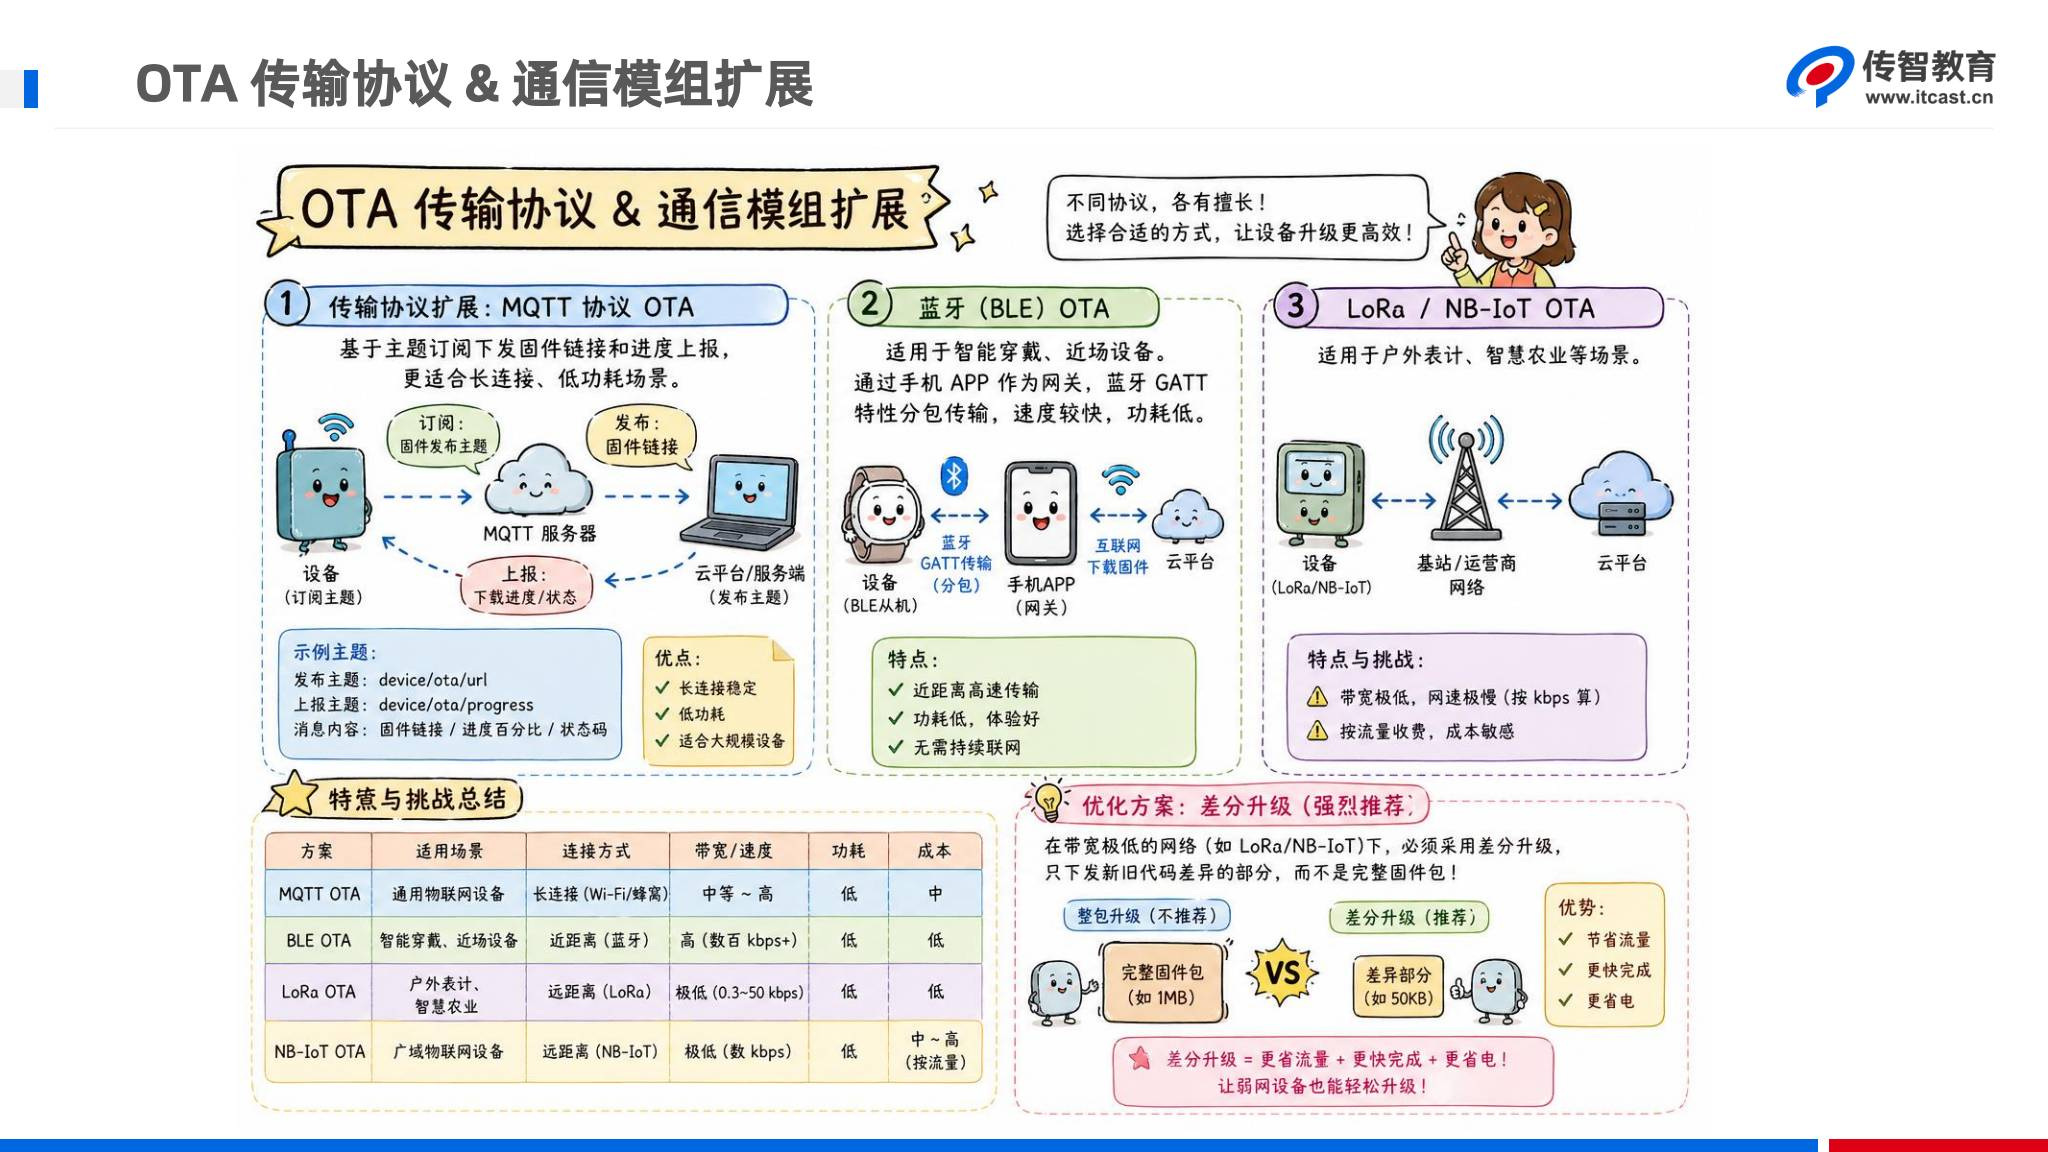

*讲义第75页，视频47对应。图中速率、功耗、距离与费用是课程概括，需按具体设备、无线参数及运营商条件评估。*

| 方案 | 课程介绍的流程 | 适用考虑 | 移植时保留的OTA职责 |
| --- | --- | --- | --- |
| HTTP/HTTPS | 查询任务，Range拉取镜像，POST结果 | 固件下载与服务端接口直观 | 身份、包类型、容量、完整性、安装与确认 |
| MQTT | 订阅升级通知/固件链接，上报进度；也可设计分块传输 | 已有连接、异步通知、设备管理 | 消息重复/顺序、链接有效期、下载或分片协议 |
| BLE | 手机先联网拿包，再通过GATT特征分片传给设备 | 穿戴、耳机、近场维护 | MTU、流控、序号、断线恢复、镜像校验 |
| LoRa/LoRaWAN | 低速远距离链路，视网络/网关设计传输 | 户外表计、智慧农业、低带宽 | 空口容量、下行限制、传输时长与能耗 |
| NB-IoT | 运营商蜂窝网络上的升级传输 | 覆盖、套餐、模块能力和电池预算 | 弱网重试、流量、包大小和升级窗口 |

几点补充边界：

- MQTT是应用层协议，Wi-Fi、蜂窝是连接承载；BLE、LoRa、NB-IoT也不是同一层级的可互换HTTP方法。方案选择要把“如何联网”和“如何传任务/镜像”分开考虑。
- MQTT不自动使OTA可靠，QoS/会话也不能替代镜像完整性、版本验证与安装恢复；常见组合是MQTT通知、HTTPS下载。
- BLE速度取决于MTU、PHY、连接间隔与流控，不能只凭“近距离”保证更快。
- LoRa点对点可以不依赖公网；LoRaWAN可能有网关和网络服务。NB-IoT通常依赖运营商蜂窝网络，不能合称“都不需要网络或资费”。
- 差分升级是低带宽时可评估的策略，是否可行还取决于包大小、基线一致性、重建内存/Flash和断电恢复，不能说所有LoRa/NB-IoT设备都必须差分。

传输层从ESP-AT换成其他模块后，`AtCmdHandle` 与二进制接收需要换掉；分区容量、完整镜像验证、参数提交和引导安全仍要重新验证，不能因为“已经连上MQTT”就跳过安装流程。


## 27. 差分升级、排错清单与系列收尾

差分包只描述旧镜像到目标镜像的变化，设备必须先确认**当前基线正是补丁所要求的版本/摘要**，再在合适区域重建新镜像，验证重建结果后安装。它不是把差异文件直接覆盖App起点。

```text
完整包：
下载完整镜像 → 验证 → 安装

差分包：
确认旧基线 → 下载补丁 → 验证补丁
  → 重建目标镜像 → 验证完整目标 → 安装
```

本课 `data.type=1` 对应完整包；`type=2` 的差分包不能进入当前直接FlashWrite的安装路径。原工程没有差分重建函数。Backup容量是否足够同时放补丁、旧数据与重建镜像，要按具体算法计算，不能只凭“补丁更小”推断一定省Flash。

最后按现象定位：

| 现象 | 优先核对 |
| --- | --- |
| 反复连Wi-Fi但已有AP | Bootloader等待的+CWJAP字符串、完整应答及超时 |
| 下载400 | URL中是否仍有%ld，产品/设备/tid/Range与鉴权是否一致 |
| 打印二进制提前结束 | %s遇NUL；看真实接收长度与十六进制 |
| 改1024后异常 | 头+payload超过底层缓冲、拆包未重组 |
| 多次写入都在Backup开头 | offset未加到地址或未推进 |
| 下载100%却App无效 | Flash返回、完整性、链接地址、App擦除边界 |
| 复制前段出现FF | 是否误擦Backup首扇区，镜像是否真正下载有效 |
| 云端一直升级中 | 101是否终结、201是否实际发送、业务code、ESP被重置 |
| 参数版本又变回旧值 | InitSysParam按编译宏覆盖，不是只看上次SetVersion |
| 有新包却解析崩溃 | Bootloader非零code未拒绝、字段类型/长度与MD5悬空 |
| 失败后长时间不进App | 网络/OTA回退循环没有全局结束策略 |
| 清标志后重启又升级 | 参数擦写结果未验证，Flash与RAM状态可能不一致 |
| 启动App无响应 | 镜像有效性、MSP/Reset_Handler、向量表与中断交接 |

自查题：

| 问题 | 应能解释的答案 |
| --- | --- |
| Backup保存的是旧App吗？ | 本实现存新镜像，不是旧版本回滚副本 |
| 为什么先格式化URL再格式化命令？ | 外层%s不会递归展开URL的任务ID占位符 |
| 32656字节按512分段最后多大？ | 63段512，末段400，共64段 |
| len非零是否代表固件有效？ | 还需范围、完整接收、任务/HTTP结果和镜像校验 |
| 为什么APP_SIZE要减1？ | 当前FlashErase按addr+arg选包含式末扇区，避免碰Backup |
| 101与201分别表示什么？ | 下载完成与升级成功，不能混成一次确认 |
| WAIT时给AtCmdHandle换201会怎样？ | 不发新命令，继续处理旧事务 |
| 课程已做MD5吗？ | 取得字段但未执行实际计算/比对，借用指针还已悬空 |
| 2秒延时能证明服务器收到201吗？ | 不能，需要响应/状态确认 |
| 下载失败与复制失败能一样清标志跳App吗？ | 不能，复制阶段App可能已不完整 |

至此，10篇笔记按原47段视频范围覆盖了课程：01概述、02 Flash、03 Ymodem、04引导跳转、05串口OTA、06 ESP-AT、07 OneNET接口、08架构状态机、09 App实现、10 Bootloader下载安装与异常处理。**知识流程已串联，实际产品所需的完整性验证、断电恢复、运行确认和发布认证仍需在工程中另行实现和测试。**

来源：视频42—47完整自动字幕；讲义69、73—75页；配套Bootloader的Wi-Fi、工具、Flash、参数、OLED、任务与工程配置；App/Versions两份bin静态摘要。字幕、源码、原图和样本指纹保存在Notebook元数据。

官方核对：[OneNET固件下载](https://open.iot.10086.cn/doc/v5/fuse/detail/1448)、[状态上报](https://open.iot.10086.cn/doc/v5/fuse/detail/1449)、[查询任务状态](https://open.iot.10086.cn/doc/v5/fuse/detail/1450)、[cJSON 1.7.7说明](https://github.com/DaveGamble/cJSON/blob/v1.7.7/README.md)。本文依据先前缓存的官方内容核对接口规则；云平台页面与设备AT固件可能更新，复现以自己的实际响应和对应版本文档为准。
